# Alzheimer's Disease Prediction

What this notebook does, step by step:

1. Load the data and take a quick look
2. Prepare it (encode text columns, split, balance the classes)
3. Pick the most useful features using 4 methods (LIME, SHAP, mRMR, RFE) and vote
4. Train 7 machine learning models and compare them
5. Predict one patient and show which features pushed the result
6. Train a DistilBERT text model and compare it with the ML models
7. Ask a small LLM (Phi-3.5) to explain the result in plain English

Sections 6 and 7 download models from Hugging Face and run best on a GPU.

## 1. Setup

In [ ]:
# Run this once. On Kaggle most of these are already installed.
%pip install -q mrmr_selection catboost shap lime imbalanced-learn lightgbm xgboost transformers datasets accelerate

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import os
import json
import warnings
from collections import Counter
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import shap
from lime.lime_tabular import LimeTabularExplainer
from mrmr import mrmr_classif
from imblearn.over_sampling import SMOTE

from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_selection import RFE
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, ConfusionMatrixDisplay)
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

warnings.filterwarnings("ignore")

In [ ]:
# Settings you may want to change
KAGGLE_PATH = ("/kaggle/input/datasets/ankushpanday1/alzheimers-prediction-dataset-global/"
               "alzheimers_prediction_dataset.csv")
LOCAL_PATH = "alzheimers_prediction_dataset.csv"
DATA_PATH = KAGGLE_PATH if os.path.exists(KAGGLE_PATH) else LOCAL_PATH

TARGET = "Alzheimer’s Diagnosis"   # note: this name uses a curly apostrophe
SEED = 42                           # makes results repeatable
TEST_SIZE = 0.3                     # 30% of patients are kept for testing

## 2. Load and look at the data

In [ ]:
data = pd.read_csv(DATA_PATH)
print("Rows and columns:", data.shape)
data.head()

Rows and columns: (74283, 25)


,Country,Age,Gender,Education Level,BMI,Physical Activity Level,Smoking Status,Alcohol Consumption,Diabetes,Hypertension,...,Dietary Habits,Air Pollution Exposure,Employment Status,Marital Status,Genetic Risk Factor (APOE-ε4 allele),Social Engagement Level,Income Level,Stress Levels,Urban vs Rural Living,Alzheimer’s Diagnosis
0,Spain,90,Male,1,33.0,Medium,Never,Occasionally,No,No,...,Healthy,High,Retired,Single,No,Low,Medium,High,Urban,No
1,Argentina,72,Male,7,29.9,Medium,Former,Never,No,No,...,Healthy,Medium,Unemployed,Widowed,No,High,Low,High,Urban,No
2,South Africa,86,Female,19,22.9,High,Current,Occasionally,No,Yes,...,Average,Medium,Employed,Single,No,Low,Medium,High,Rural,No
3,China,53,Male,17,31.2,Low,Never,Regularly,Yes,No,...,Healthy,Medium,Retired,Single,No,High,Medium,Low,Rural,No
4,Sweden,58,Female,3,30.0,High,Former,Never,Yes,No,...,Unhealthy,High,Employed,Married,No,Low,Medium,High,Rural,No


In [ ]:
print("Missing values per column:")
print(data.isnull().sum()[data.isnull().sum() > 0])
print("\nDuplicate rows:", data.duplicated().sum())

print("\nTarget balance:")
print(data[TARGET].value_counts())

Missing values per column:
Series([], dtype: int64)

Duplicate rows: 0

Target balance:
Alzheimer’s Diagnosis
No     43570
Yes    30713
Name: count, dtype: int64


## 3. Prepare the data

- Text columns (like "Low" / "High") are turned into numbers. We keep the encoders so we can reuse them for new patients later.
- The data is split into train and test **before** any balancing, so the test set stays untouched.
- Missing numbers are filled with the median.
- SMOTE balances the classes by creating synthetic examples. It is only used on the **training** data.

In [ ]:
# 1) Turn text into numbers (each column is encoded once)
df = data.copy()
encoders = {}
for col in df.select_dtypes(include="object").columns:
    encoders[col] = LabelEncoder()
    df[col] = encoders[col].fit_transform(df[col].astype(str))

X = df.drop(columns=TARGET)
y = df[TARGET]          # "No" -> 0, "Yes" -> 1

# 2) Split into train and test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=SEED, stratify=y
)
train_index = X_train.index   # remembered so the text model uses the exact same patients

# 3) Fill missing values (learned from the training data only)
imputer = SimpleImputer(strategy="median")
X_train = pd.DataFrame(imputer.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test = pd.DataFrame(imputer.transform(X_test), columns=X.columns, index=X_test.index)

# 4) Balance the training data
X_train_bal, y_train_bal = SMOTE(random_state=SEED).fit_resample(X_train, y_train)

print("Train size before balancing:", len(X_train), "-> after:", len(X_train_bal))
print("Test size:", len(X_test))

Train size before balancing: 51998 -> after: 60998
Test size: 22285


## 4. Choose the best features

Four different methods each pick their top 10 features. A feature picked by more methods is more trustworthy.

- **LIME**: explains single predictions, then we average over many patients
- **SHAP**: measures how much each feature moves the prediction
- **mRMR**: picks features that matter for the target but don't repeat each other
- **RFE**: repeatedly removes the weakest feature

In [ ]:
TOP_K = 10

# A Random Forest is used as the "reference" model for LIME and SHAP
rf_reference = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)
rf_reference.fit(X_train_bal, y_train_bal)

# 100 random test patients to explain
X_sample = X_test.sample(n=100, random_state=SEED)


def top_features_lime():
    explainer = LimeTabularExplainer(
        X_train_bal.values,
        feature_names=list(X.columns),
        class_names=["No", "Yes"],
        mode="classification",
        random_state=SEED,
    )
    predict = lambda arr: rf_reference.predict_proba(pd.DataFrame(arr, columns=X.columns))

    scores = np.zeros(X.shape[1])
    for row in X_sample.values:
        explanation = explainer.explain_instance(row, predict, num_features=TOP_K)
        for feature_number, weight in explanation.local_exp[1]:
            scores[feature_number] += abs(weight)

    ranking = pd.Series(scores / len(X_sample), index=X.columns).sort_values(ascending=False)
    return ranking.head(TOP_K).index.tolist()


def top_features_shap():
    values = shap.TreeExplainer(rf_reference).shap_values(X_sample)
    # Depending on the SHAP version the result is a list or a 3D array; we want the "Yes" class
    if isinstance(values, list):
        values = values[1]
    elif values.ndim == 3:
        values = values[:, :, 1]
    ranking = pd.Series(np.abs(values).mean(axis=0), index=X.columns).sort_values(ascending=False)
    return ranking.head(TOP_K).index.tolist()


def top_features_mrmr():
    return mrmr_classif(X=X_train_bal, y=y_train_bal, K=TOP_K, show_progress=False)


def top_features_rfe():
    model = LGBMClassifier(n_estimators=200, learning_rate=0.05, random_state=SEED, verbosity=-1)
    rfe = RFE(estimator=model, n_features_to_select=TOP_K, step=1)
    rfe.fit(X_train_bal, y_train_bal)
    return X.columns[rfe.support_].tolist()


rankings = {
    "LIME": top_features_lime(),
    "SHAP": top_features_shap(),
    "mRMR": top_features_mrmr(),
    "RFE": top_features_rfe(),
}

for name, features in rankings.items():
    print(f"{name}: {features}\n")

LIME: ['Family History of Alzheimer’s', 'Genetic Risk Factor (APOE-ε4 allele)', 'Age', 'Cholesterol Level', 'Gender', 'Urban vs Rural Living', 'Hypertension', 'Alcohol Consumption', 'Smoking Status', 'Air Pollution Exposure']

SHAP: ['Age', 'Genetic Risk Factor (APOE-ε4 allele)', 'Family History of Alzheimer’s', 'Country', 'Urban vs Rural Living', 'Gender', 'Alcohol Consumption', 'Hypertension', 'Cognitive Test Score', 'BMI']

mRMR: ['Age', 'Genetic Risk Factor (APOE-ε4 allele)', 'Family History of Alzheimer’s', 'Country', 'Physical Activity Level', 'Hypertension', 'Stress Levels', 'Dietary Habits', 'Income Level', 'Smoking Status']

RFE: ['Country', 'Age', 'Education Level', 'BMI', 'Physical Activity Level', 'Alcohol Consumption', 'Family History of Alzheimer’s', 'Cognitive Test Score', 'Genetic Risk Factor (APOE-ε4 allele)', 'Social Engagement Level']



### How much do the methods agree?
Jaccard similarity = shared features ÷ all features picked by either method (1.0 means identical lists).

In [ ]:
def jaccard(a, b):
    a, b = set(a), set(b)
    return len(a & b) / len(a | b)


for first, second in combinations(rankings, 2):
    print(f"{first} vs {second}: {jaccard(rankings[first], rankings[second]):.2f}")

LIME vs SHAP: 0.54
LIME vs mRMR: 0.33
LIME vs RFE: 0.25
SHAP vs mRMR: 0.33
SHAP vs RFE: 0.54
mRMR vs RFE: 0.33


### Vote: which features were picked most often?

In [ ]:
votes = Counter(f for features in rankings.values() for f in features)
vote_table = pd.DataFrame(votes.most_common(), columns=["Feature", "Votes"])
vote_table.head(15)

,Feature,Votes
0,Family History of Alzheimer’s,4
1,Genetic Risk Factor (APOE-ε4 allele),4
2,Age,4
3,Hypertension,3
4,Alcohol Consumption,3
5,Country,3
6,Gender,2
7,Urban vs Rural Living,2
8,Smoking Status,2
9,Cognitive Test Score,2


In [ ]:
# The 15 features chosen from the vote. They are written out here so every run uses the same list.
# To use the fresh vote instead, replace this list with: vote_table["Feature"].head(15).tolist()
FEATURES = [
    "Age",
    "Employment Status",
    "Genetic Risk Factor (APOE-ε4 allele)",
    "Family History of Alzheimer’s",
    "Stress Levels",
    "Urban vs Rural Living",
    "Sleep Quality",
    "Depression Level",
    "Hypertension",
    "Gender",
    "Air Pollution Exposure",
    "Dietary Habits",
    "Physical Activity Level",
    "Diabetes",
    "Alcohol Consumption",
]

top_voted = set(vote_table["Feature"].head(15))
print("Chosen features that are also in this run's top 15 votes:", len(top_voted & set(FEATURES)), "of 15")

Chosen features that are also in this run's top 15 votes: 10 of 15


## 5. Train and compare machine learning models

Every model uses the same 15 features, the same train/test split, and the same scaling.

In [ ]:
# Scale the numbers so they are on a similar range (fit on train only)
scaler = StandardScaler()
X_train_sc = pd.DataFrame(scaler.fit_transform(X_train_bal[FEATURES]), columns=FEATURES)
X_test_sc = pd.DataFrame(scaler.transform(X_test[FEATURES]), columns=FEATURES)

models = {
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.005, random_state=SEED),
    "LightGBM": LGBMClassifier(n_estimators=200, learning_rate=0.05, random_state=SEED, verbosity=-1),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, random_state=SEED),
    "AdaBoost": AdaBoostClassifier(n_estimators=200, learning_rate=0.05, random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=4, min_samples_split=5, random_state=SEED),
    "CatBoost": CatBoostClassifier(iterations=1000, learning_rate=0.05, depth=6, random_seed=SEED, verbose=0),
    "MLP (neural network)": MLPClassifier(hidden_layer_sizes=(128, 64, 32), alpha=1e-3, max_iter=800,
                                          early_stopping=True, random_state=SEED),
}

trained = {}
rows = []
for name, model in models.items():
    model.fit(X_train_sc, y_train_bal)
    predictions = model.predict(X_test_sc)
    probabilities = model.predict_proba(X_test_sc)[:, 1]
    rows.append({
        "Model": name,
        "Train accuracy": model.score(X_train_sc, y_train_bal),
        "Test accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
    })
    trained[name] = model

results = pd.DataFrame(rows).sort_values("F1", ascending=False).reset_index(drop=True)
results.round(4)

,Model,Train accuracy,Test accuracy,Precision,Recall,F1,ROC-AUC
0,AdaBoost,0.7418,0.7241,0.6415,0.7542,0.6933,0.7934
1,XGBoost,0.7554,0.7261,0.6496,0.7330,0.6888,0.7945
2,Gradient Boosting,0.7670,0.7261,0.6495,0.7330,0.6888,0.7945
3,LightGBM,0.7713,0.7252,0.6496,0.7278,0.6865,0.7946
4,Random Forest,0.7562,0.7235,0.6491,0.7214,0.6833,0.7907
5,CatBoost,0.7882,0.7208,0.6544,0.6878,0.6707,0.7924
6,MLP (neural network),0.7586,0.7069,0.6339,0.6892,0.6604,0.7739


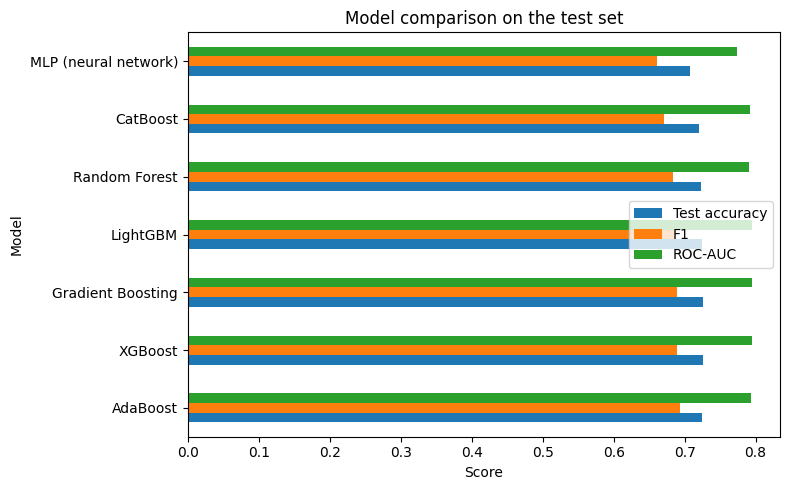

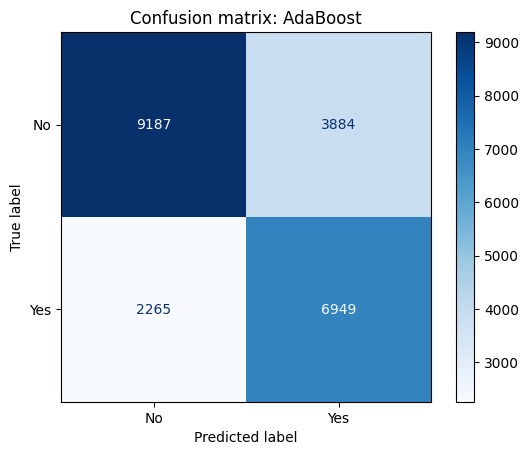

In [ ]:
results.set_index("Model")[["Test accuracy", "F1", "ROC-AUC"]].plot.barh(figsize=(8, 5))
plt.title("Model comparison on the test set")
plt.xlabel("Score")
plt.tight_layout()
plt.show()

best_name = results.loc[0, "Model"]
ConfusionMatrixDisplay.from_estimator(trained[best_name], X_test_sc, y_test,
                                      display_labels=["No", "Yes"], cmap="Blues")
plt.title(f"Confusion matrix: {best_name}")
plt.show()

### Optional: tune XGBoost
This tries a few settings and keeps the best one. It can take a few minutes. Skip it if you are short on time.

In [ ]:
param_grid = {
    "n_estimators": [200, 400],
    "max_depth": [3, 5],
    "learning_rate": [0.03, 0.1],
}

search = GridSearchCV(
    XGBClassifier(random_state=SEED),
    param_grid,
    scoring="accuracy",
    cv=3,
    n_jobs=1,
    verbose=1,
)
search.fit(X_train_sc, y_train_bal)

print("Best settings:", search.best_params_)
print("Test accuracy with tuned model:", round(search.best_estimator_.score(X_test_sc, y_test), 4))

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best settings: {'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 200}
Test accuracy with tuned model: 0.7261


## 6. Predict one patient and explain why

`predict_patient` takes a patient written in plain words, converts it the same way as the training data,
and returns the prediction plus the 5 features that influenced it most.

- Positive SHAP value: pushes toward Alzheimer's
- Negative SHAP value: pushes away from Alzheimer's

In [ ]:
patient = {
    "Age": 80,
    "Employment Status": "Unemployed",
    "Genetic Risk Factor (APOE-ε4 allele)": "No",
    "Family History of Alzheimer’s": "No",
    "Stress Levels": "Low",
    "Urban vs Rural Living": "Rural",
    "Sleep Quality": "Good",
    "Depression Level": "Medium",
    "Hypertension": "Yes",
    "Gender": "Female",
    "Air Pollution Exposure": "Low",
    "Dietary Habits": "Healthy",
    "Physical Activity Level": "Medium",
    "Diabetes": "No",
    "Alcohol Consumption": "Never",
}

In [ ]:
def predict_patient(patient, model_name="XGBoost", top_n=5):
    model = trained[model_name]

    # Same preparation as the training data: text -> numbers -> scaled
    row = pd.DataFrame([patient])[FEATURES]
    for col in FEATURES:
        if col in encoders:
            row[col] = encoders[col].transform(row[col])
    row_sc = pd.DataFrame(scaler.transform(row), columns=FEATURES)

    probability = model.predict_proba(row_sc)[0]

    # SHAP: how much did each feature move the "Yes" probability?
    predict_yes = lambda arr: model.predict_proba(pd.DataFrame(arr, columns=FEATURES))[:, 1]
    background = shap.sample(X_train_sc, 100, random_state=SEED)
    shap_result = shap.Explainer(predict_yes, background)(row_sc)

    contributions = pd.Series(shap_result.values[0], index=FEATURES)
    top = contributions.reindex(contributions.abs().sort_values(ascending=False).index).head(top_n)

    return {
        "Model": model_name,
        "Prediction": "Yes" if probability[1] >= 0.5 else "No",
        "Alzheimer_probability": round(float(probability[1]) * 100, 2),
        "Non_Alzheimer_probability": round(float(probability[0]) * 100, 2),
        "Important_features": {name: round(float(value), 4) for name, value in top.items()},
    }


ml_output = predict_patient(patient, "XGBoost")
print(json.dumps(ml_output, indent=2, ensure_ascii=False))

{
  "Model": "XGBoost",
  "Prediction": "Yes",
  "Alzheimer_probability": 56.64,
  "Non_Alzheimer_probability": 43.36,
  "Important_features": {
    "Age": 0.1697,
    "Genetic Risk Factor (APOE-ε4 allele)": -0.0512,
    "Family History of Alzheimer’s": -0.0383,
    "Hypertension": -0.0073,
    "Alcohol Consumption": -0.004
  }
}


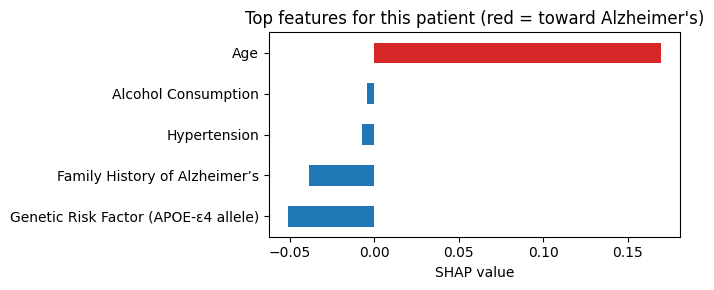

In [ ]:
pd.Series(ml_output["Important_features"]).sort_values().plot.barh(
    color=["tab:blue" if v < 0 else "tab:red" for v in pd.Series(ml_output["Important_features"]).sort_values()],
    figsize=(7, 3),
)
plt.title("Top features for this patient (red = toward Alzheimer's)")
plt.xlabel("SHAP value")
plt.tight_layout()
plt.show()

## 7. Text model: DistilBERT

Here each patient is written as a short sentence like `Age: 80. Gender: Female. ...` and DistilBERT learns from the text.
It uses the **same train and test patients** as the ML models, so the comparison is fair.

Training is slow on a CPU. Use a GPU, or lower `EPOCHS`.

In [ ]:
import torch
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding,
                          Trainer, TrainingArguments)
from scipy.special import softmax

BERT_NAME = "distilbert/distilbert-base-uncased"
MAX_LENGTH = 256
EPOCHS = 2
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using:", device)

Using: cpu


In [ ]:
def to_text(record):
    # Turns one patient (dict or row) into a sentence
    return " ".join(f"{col}: {record[col]}." for col in FEATURES)


all_text = data[FEATURES].apply(to_text, axis=1)
train_ids = train_index
test_ids = X_test.index

train_data = Dataset.from_dict({"text": all_text.loc[train_ids].tolist(), "label": y.loc[train_ids].tolist()})
test_data = Dataset.from_dict({"text": all_text.loc[test_ids].tolist(), "label": y.loc[test_ids].tolist()})

bert_tokenizer = AutoTokenizer.from_pretrained(BERT_NAME)


def tokenize(batch):
    return bert_tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)


train_data = train_data.map(tokenize, batched=True, remove_columns=["text"])
test_data = test_data.map(tokenize, batched=True, remove_columns=["text"])

print(all_text.iloc[0])

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/51998 [00:00<?, ? examples/s]

Map:   0%|          | 0/22285 [00:00<?, ? examples/s]

Age: 90. Employment Status: Retired. Genetic Risk Factor (APOE-ε4 allele): No. Family History of Alzheimer’s: No. Stress Levels: High. Urban vs Rural Living: Urban. Sleep Quality: Poor. Depression Level: Low. Hypertension: No. Gender: Male. Air Pollution Exposure: High. Dietary Habits: Healthy. Physical Activity Level: Medium. Diabetes: No. Alcohol Consumption: Occasionally.


In [ ]:
bert_model = AutoModelForSequenceClassification.from_pretrained(
    BERT_NAME, num_labels=2, id2label={0: "No", 1: "Yes"}, label2id={"No": 0, "Yes": 1}
)


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    probabilities = softmax(logits, axis=1)[:, 1]
    return {
        "accuracy": accuracy_score(labels, predictions),
        "precision": precision_score(labels, predictions, zero_division=0),
        "recall": recall_score(labels, predictions, zero_division=0),
        "f1": f1_score(labels, predictions, zero_division=0),
        "roc_auc": roc_auc_score(labels, probabilities),
    }


training_args = TrainingArguments(
    output_dir="distilbert_alzheimer",
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    learning_rate=2e-5,
    weight_decay=0.01,
    warmup_steps=200,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    fp16=torch.cuda.is_available(),
    logging_steps=100,
    seed=SEED,
    report_to="none",
)

trainer = Trainer(
    model=bert_model,
    args=training_args,
    train_dataset=train_data,
    eval_dataset=test_data,
    data_collator=DataCollatorWithPadding(bert_tokenizer),
    processing_class=bert_tokenizer,
    compute_metrics=compute_metrics,
)

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
trainer.train()
bert_scores = trainer.evaluate()
print(bert_scores)

Epoch,Training Loss,Validation Loss


In [ ]:
def predict_patient_bert(patient):
    inputs = bert_tokenizer(to_text(patient), truncation=True, max_length=MAX_LENGTH, return_tensors="pt")
    inputs = {key: value.to(bert_model.device) for key, value in inputs.items()}
    bert_model.eval()
    with torch.no_grad():
        probability = torch.softmax(bert_model(**inputs).logits, dim=1)[0]
    return {
        "Model": "DistilBERT",
        "Prediction": "Yes" if probability[1] >= 0.5 else "No",
        "Alzheimer_probability": round(float(probability[1]) * 100, 2),
        "Non_Alzheimer_probability": round(float(probability[0]) * 100, 2),
    }


bert_output = predict_patient_bert(patient)
print(bert_output)

In [ ]:
# Side by side with the ML models
comparison = results[["Model", "Test accuracy", "F1", "ROC-AUC"]].copy()
bert_row = pd.DataFrame([{
    "Model": "DistilBERT (text)",
    "Test accuracy": bert_scores["eval_accuracy"],
    "F1": bert_scores["eval_f1"],
    "ROC-AUC": bert_scores["eval_roc_auc"],
}])
pd.concat([comparison, bert_row], ignore_index=True).sort_values("F1", ascending=False).round(4)

## 8. Plain-English explanation with an LLM

Phi-3.5 reads both model outputs and writes a short explanation. It is told not to diagnose or invent
medical facts. This is a research demo and **not** medical advice.

In [ ]:
from transformers import AutoModelForCausalLM

LLM_NAME = "microsoft/Phi-3.5-mini-instruct"
llm_tokenizer = AutoTokenizer.from_pretrained(LLM_NAME)
llm = AutoModelForCausalLM.from_pretrained(
    LLM_NAME,
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    device_map="auto",
)

In [ ]:
prompt = f"""
You are explaining the output of an Alzheimer's risk prediction system to a non-expert.

ML model output:
{json.dumps(ml_output, indent=2, ensure_ascii=False)}

DistilBERT output:
{json.dumps(bert_output, indent=2)}

Rules:
- Keep the probabilities exactly as given.
- Say whether the two models agree.
- Explain each of the five important features in one sentence.
- A positive SHAP value pushes toward Alzheimer's, a negative one pushes away from it.
- Do not diagnose the patient, do not claim a medical cause, and do not invent clinical facts.
- Keep it short.
"""

messages = [
    {"role": "system", "content": "You are a careful assistant that explains model predictions."},
    {"role": "user", "content": prompt},
]

inputs = llm_tokenizer.apply_chat_template(
    messages, add_generation_prompt=True, return_dict=True, return_tensors="pt"
).to(llm.device)

with torch.inference_mode():
    output_ids = llm.generate(
        **inputs,
        max_new_tokens=400,
        do_sample=False,
        repetition_penalty=1.1,
        pad_token_id=llm_tokenizer.eos_token_id,
    )

answer = llm_tokenizer.decode(output_ids[0][inputs["input_ids"].shape[-1]:], skip_special_tokens=True)
print(answer)